In [1]:
MODEL_CODE = "xgb"
MODEL_NAME = "XGBoost"

# 08: XGBoost Modeli

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini · **Model ailesi:** boosting

**XGBoost (Extreme Gradient Boosting)** ağaçları **sırayla** kurar: her yeni ağaç, önceki ağaçların toplamının yaptığı hataları düzeltmeye odaklanır. Random Forest'ta ağaçlar birbirinden bağımsız kurulup oylanır (bagging); boosting'de ise zayıf ağaçlar art arda eklenerek güçlü bir model elde edilir. XGBoost ağaçları **seviye seviye** (dengeli) büyütür ve ağaç sayısı, derinlik ve öğrenme hızı ile düzenlileştirilir.

Ağaç tabanlı olduğu için ölçeklemeden etkilenmez; ortak pipeline'daki ölçekleme sonucu değiştirmez.

**Dengesizlik:** XGBoost'ta `class_weight` parametresi yoktur. Ekip kuralı gereği `balancing="none"` ile birlikte `scale_pos_weight = (inme yok sayısı / inme var sayısı)` kullanılır: model inme vakalarındaki hatayı bu oranda daha ağır cezalandırır. SMOTE ile de karşılaştırılır.

**Bu notebook'ta yapılanlar:** hiperparametre araması · max_depth'in overfitting'e etkisi · dengeleme yöntemi karşılaştırması · feature engineering etkisi · CV değerlendirmesi ve eşik seçimi · öğrenme eğrisi · test seti · XAI

## 1. Kurulum

In [2]:
# shap and lime are not preinstalled on Colab
try:
    import lime
    import shap
except ImportError:
    %pip install -q shap lime

In [3]:
import sys
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

# Çıktı klasörleri: repo kökünde models/ ve figures/ (Colab'da çalışma klasöründe)
ROOT = SRC_DIR.resolve().parent if SRC_DIR.name == "src" else Path(".")
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "figures";   FIG_DIR.mkdir(exist_ok=True)

import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

from config import MAIN_METRIC, RANDOM_STATE, TARGET_RECALL
from preprocessing import build_pipeline, load_data, scale_pos_weight
from metrics import (SCORING, cv_evaluate, learning_curve_analysis, shared_cv, test_evaluate,
                     threshold_analysis)
from explain import explain

warnings.filterwarnings("ignore")

## 2. Veri

`train.csv` / `test.csv`. Ön işleme (feature engineering, encoding, ölçekleme, SMOTE) `build_pipeline()` içinde yapılır; test seti en sona kadar kullanılmaz.

In [4]:
X_train, X_test, y_train, y_test = load_data()
print("Eğitim:", X_train.shape, f"| inme: {y_train.sum()} kişi ({y_train.mean():.2%})")
print("Test:  ", X_test.shape, f"| inme: {y_test.sum()} kişi ({y_test.mean():.2%})")

# scale_pos_weight yalnızca eğitim verisinden hesaplanır
SPW = scale_pos_weight(y_train)
print(f"scale_pos_weight = {SPW:.2f}  (her inme vakası ~{SPW:.0f} kat ağırlıklı)")

Eğitim: (3521, 17) | inme: 306 kişi (8.69%)
Test:   (881, 17) | inme: 77 kişi (8.74%)
scale_pos_weight = 10.51  (her inme vakası ~11 kat ağırlıklı)


## 3. Hiperparametre araması

| Parametre | Değerler | Anlamı |
|---|---|---|
| `n_estimators` | 50, 100, 200 | Ağaç sayısı. Fazla ağaç eğitim verisine giderek daha sıkı uyar |
| `learning_rate` | 0.01, 0.03, 0.1 | Her ağacın katkısı. Küçük öğrenme hızı daha temkinli ilerler, daha fazla ağaç ister ama genelde daha iyi genelleşir |
| `max_depth` | 1, 2, 3, 5 | Ağaç derinliği. Derin ağaçlar karmaşık etkileşimleri öğrenir ama ezberleme (overfitting) riski artar. `max_depth=1` tek bölmeli ağaçtır (her ağaç tek bir özelliğe bakar) |
| `min_child_weight` | 1, 5, 10 | Bir yaprakta bulunması gereken minimum ağırlık. Büyük değer küçük, gürültülü grupları bölmeyi engeller |

Sabit: `subsample=0.8`, `colsample_bytree=0.8` (her ağaç satırların ve sütunların %80'iyle kurulur; overfitting'i azaltır).

Ortak katlar (`shared_cv()`) ve ortak metrikler (`SCORING`) kullanılır; en iyi model `MAIN_METRIC` (PR-AUC) ile seçilir. Dengeleme: `scale_pos_weight`.

In [5]:
def search_table(search, params):
    """Hiperparametre denemeleri: eğitim ve CV skoru, aradaki fark (overfitting göstergesi)."""
    r = pd.DataFrame(search.cv_results_)
    t = r[[f"param_{p}" for p in params]].copy()
    t.columns = [p.replace("model__", "") for p in params]
    for m in [MAIN_METRIC, "recall", "roc_auc"]:
        t[f"{m}_cv"] = r[f"mean_test_{m}"]
    t[f"{MAIN_METRIC}_train"] = r[f"mean_train_{MAIN_METRIC}"]
    t["fark (train - cv)"] = t[f"{MAIN_METRIC}_train"] - t[f"{MAIN_METRIC}_cv"]
    return t.sort_values(f"{MAIN_METRIC}_cv", ascending=False).round(4)

In [6]:
params = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.01, 0.03, 0.1],
    "model__max_depth": [1, 2, 3, 5],
    "model__min_child_weight": [1, 5, 10],
}
start = time.time()
search = GridSearchCV(build_pipeline(XGBClassifier(scale_pos_weight=SPW, eval_metric="logloss", tree_method="hist",
                      subsample=0.8, colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE),
                                     balancing="none"),
                      params, cv=shared_cv(), scoring=SCORING, refit=MAIN_METRIC,
                      n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
best = search.best_estimator_

print(f"Süre: {time.time() - start:.0f} sn")
print("En iyi parametreler:", search.best_params_)
print(f"En iyi CV {MAIN_METRIC}: {search.best_score_:.4f}")
search_table(search, list(params)).head(10)

Süre: 13 sn
En iyi parametreler: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_child_weight': 1, 'model__n_estimators': 50}
En iyi CV pr_auc: 0.2149


,n_estimators,learning_rate,max_depth,min_child_weight,pr_auc_cv,recall_cv,roc_auc_cv,pr_auc_train,fark (train - cv)
45,50,0.03,2,1,0.2149,0.6436,0.7160,0.2472,0.0323
48,50,0.03,2,5,0.2149,0.6502,0.7160,0.2495,0.0346
51,50,0.03,2,10,0.2137,0.6469,0.7161,0.2473,0.0336
16,100,0.01,2,10,0.2113,0.6470,0.7159,0.2389,0.0277
13,100,0.01,2,5,0.2108,0.6502,0.7160,0.2387,0.0279
37,100,0.03,1,1,0.2099,0.6502,0.7175,0.2247,0.0148
40,100,0.03,1,5,0.2099,0.6502,0.7175,0.2247,0.0148
43,100,0.03,1,10,0.2099,0.6502,0.7175,0.2247,0.0148
14,200,0.01,2,5,0.2096,0.6469,0.7166,0.2554,0.0458
44,200,0.03,1,10,0.2089,0.6534,0.7182,0.2402,0.0313


### Ağaç derinliğinin etkisi (overfitting)

Ağaç derinliği (`max_depth`) arttıkça model eğitim verisine daha sıkı uyar ve eğitim skoru yükselir. CV skoru aynı oranda artmıyorsa, hatta düşüyorsa model ezberlemeye başlamıştır. Grafikte diğer parametreler en iyi değerlerinde sabit tutulur.

**Early stopping hakkında:** Boosting'de overfitting'i önlemenin bilinen bir yolu, doğrulama skoru iyileşmeyi bıraktığında ağaç eklemeyi durdurmaktır (early stopping). Ortak pipeline'da doğrulama verisinin de ön işlemeden geçirilmesi gerektiği için burada kullanılmadı; bunun yerine ağaç sayısı, öğrenme hızı ve derinlik aramayla birlikte seçildi ve öğrenme eğrisiyle kontrol edildi.

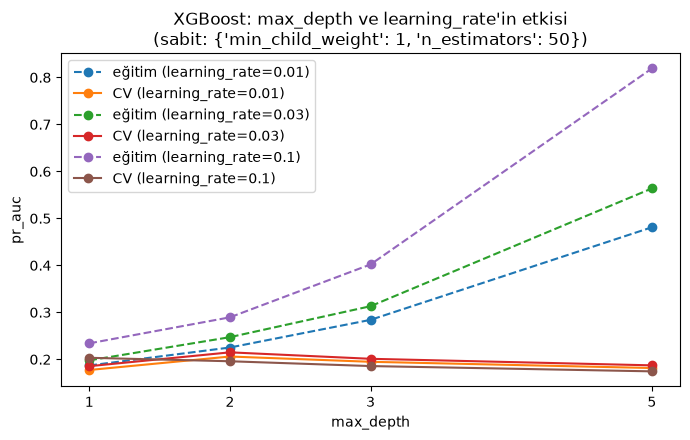

In [7]:
r = pd.DataFrame(search.cv_results_)
x_param = "model__max_depth"
fixed = {k: v for k, v in search.best_params_.items() if k not in (x_param, "model__learning_rate")}
mask = np.logical_and.reduce([r[f"param_{k}"] == v for k, v in fixed.items()])

fig, ax = plt.subplots(figsize=(7, 4.5))
for lr in params["model__learning_rate"]:
    sub = r[mask & (r["param_model__learning_rate"] == lr)].sort_values(f"param_{x_param}")
    x = sub[f"param_{x_param}"].astype(int)
    ax.plot(x, sub[f"mean_train_{MAIN_METRIC}"], "o--", label=f"eğitim (learning_rate={lr})")
    ax.plot(x, sub[f"mean_test_{MAIN_METRIC}"], "o-", label=f"CV (learning_rate={lr})")
ax.set_xticks(params[x_param])
ax.set_xlabel("max_depth")
ax.set_ylabel(MAIN_METRIC)
ax.set_title(f"XGBoost: max_depth ve learning_rate'in etkisi\n(sabit: { {k.replace('model__', ''): v for k, v in fixed.items()} })")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_max_depth_overfitting.png", dpi=200)
plt.show()

## 4. Dengeleme yöntemi: scale_pos_weight mı, SMOTE mu?

İki seçenek karşılaştırılır: **scale_pos_weight** (veri değişmez, gerçek inme vakalarındaki hata daha ağır cezalandırılır) ve **SMOTE** (azınlık sınıfı için sentetik hasta üretilir). Ağaç modelleri SMOTE'un ürettiği sentetik örnekleri ezberleyebildiği için bu karşılaştırma özellikle önemlidir. En iyi parametrelerle ikisi karşılaştırılır (bu deneyler `results.csv`'ye yazılmaz).

In [8]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}

def make_model(balancing, feature_engineering=True):
    """En iyi parametrelerle model. scale_pos_weight yalnızca SMOTE kullanılmıyorsa verilir."""
    weight = {"scale_pos_weight": SPW} if balancing == "none" else {}
    return build_pipeline(XGBClassifier(eval_metric="logloss", tree_method="hist", subsample=0.8,
                      colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, **best_params, **weight),
                          balancing=balancing, feature_engineering=feature_engineering)

options = {"scale_pos_weight": "none", "smote": "smote"}
rows = {}
for label, balancing in options.items():
    res = cv_evaluate(make_model(balancing), X_train, y_train, model_name=f"{MODEL_NAME} ({label})",
                      save=False, verbose=False)
    rows[label] = res["summary"]["cv_mean"]
balance_table = pd.DataFrame(rows).T.round(3)
balance_table

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
scale_pos_weight,0.644,0.154,0.248,0.663,0.716,0.215,0.661
smote,0.604,0.146,0.236,0.664,0.696,0.172,0.659


## 5. Feature engineering'in etkisi

Ortak pipeline 5 yeni özellik ekler (17 → 28 sütun). Ağaç modelleri eşik değerlerini kendileri öğrenebildiği için tansiyon evresi gibi kategoriler onlara ham değerlerden daha az bilgi katabilir. En iyi parametrelerle feature engineering açık ve kapalı karşılaştırılır (bu deneyler `results.csv`'ye yazılmaz).

In [9]:
rows = {}
for fe in [True, False]:
    res = cv_evaluate(make_model("none", feature_engineering=fe), X_train, y_train,
                      model_name=f"{MODEL_NAME} (FE={fe})", save=False, verbose=False)
    rows["FE açık" if fe else "FE kapalı"] = res["summary"]["cv_mean"]
pd.DataFrame(rows).T.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
FE açık,0.644,0.154,0.248,0.663,0.716,0.215,0.661
FE kapalı,0.670,0.155,0.251,0.651,0.716,0.205,0.653


## 6. Final model: CV değerlendirmesi

Seçilen model ortak `cv_evaluate` ile değerlendirilir ve sonucu `results.csv`'ye **bir satır** olarak eklenir. Karşılaştırma notebook'u bu satırı kullanır. Eğitim ve CV skorları arasındaki fark (`gap`) overfitting göstergesidir.

In [10]:
# SMOTE, scale_pos_weight'dan daha iyi PR-AUC verdiyse final model onunla kurulur
if balance_table.loc["smote", MAIN_METRIC] > balance_table.loc["scale_pos_weight", MAIN_METRIC]:
    best = make_model("smote")
    chosen_balancing = "smote"
else:
    chosen_balancing = "scale_pos_weight"
print("Seçilen dengeleme:", chosen_balancing)

cv_result = cv_evaluate(best, X_train, y_train, model_name=MODEL_NAME,
                        note=f"{chosen_balancing} + XGBoost, GridSearch: {best_params}")

Seçilen dengeleme: scale_pos_weight


===== XGBoost: 5 katlı CV (eşik = 0.5) =====
Kat başına ortalama eğitim süresi: 0.04 sn

             train_mean  cv_mean  cv_std    gap
metric                                         
recall            0.725    0.644   0.065  0.081
precision         0.173    0.154   0.013  0.019
f1                0.279    0.248   0.021  0.031
specificity       0.669    0.663   0.029  0.007
roc_auc           0.765    0.716   0.015  0.049
pr_auc            0.247    0.215   0.026  0.032
accuracy          0.674    0.661   0.024  0.013

Sonuç 'results.csv' dosyasına eklendi.


## 7. Eşik seçimi

Varsayılan eşik 0.5'tir, ama inmeyi kaçırmak yanlış alarmdan pahalı olduğu için eşik, **test setine bakılmadan** CV tahminleri (OOF) üzerinde seçilir: hedef recall'u (%80) en az yanlış alarmla sağlayan eşik.

===== XGBoost: Eşik analizi (toplam 306 inme, 3521 kişi) =====
 threshold  caught  missed  false_alarms  recall  precision  specificity  false_alarms_per_1000
      0.05     306       0          3215   1.000      0.087        0.000                913.093
      0.10     306       0          3215   1.000      0.087        0.000                913.093
      0.15     306       0          3215   1.000      0.087        0.000                913.093
      0.20     306       0          3215   1.000      0.087        0.000                913.093
      0.25     306       0          3204   1.000      0.087        0.003                909.969
      0.30     294      12          2705   0.961      0.098        0.159                768.248
      0.35     278      28          2108   0.908      0.117        0.344                598.694
      0.40     259      47          1792   0.846      0.126        0.443                508.946
      0.45     235      71          1479   0.768      0.137        0.540 

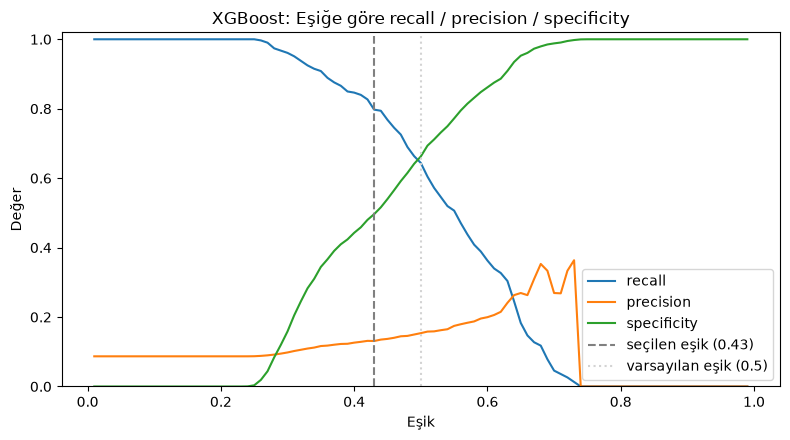

In [11]:
table, threshold = threshold_analysis(cv_result["y"], cv_result["oof_score"], model_name=MODEL_NAME)

## 8. Overfitting kontrolü: öğrenme eğrisi

Eğitim verisi büyüdükçe eğitim ve CV skorları birbirine yaklaşıyorsa model genelleşiyor demektir. Büyük ve kapanmayan bir fark overfitting, ikisinin birlikte düşük kalması underfitting gösterir.

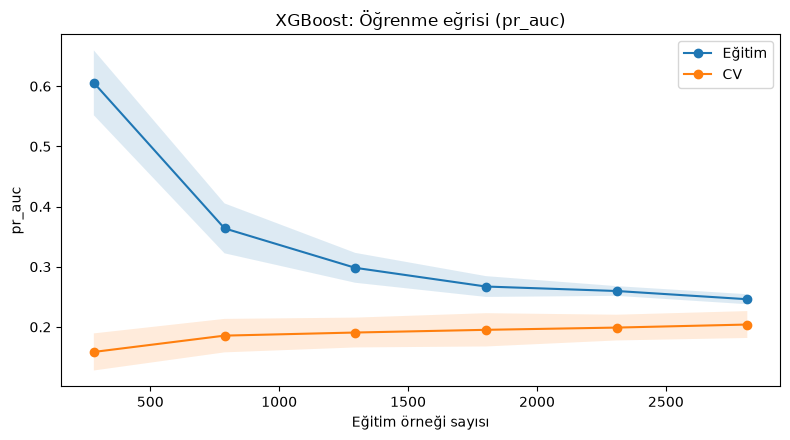

,train_size,train_mean,cv_mean,cv_std
0,281,0.606,0.158,0.031
1,788,0.364,0.186,0.028
2,1295,0.298,0.191,0.025
3,1802,0.267,0.195,0.028
4,2309,0.260,0.199,0.021
5,2816,0.246,0.204,0.022


In [12]:
lc = learning_curve_analysis(best, X_train, y_train, model_name=MODEL_NAME)
lc.round(3)

## 9. Test seti (yalnızca bir kez)

Final model tüm eğitim verisiyle yeniden eğitilir, seçilen eşikle test setinde değerlendirilir ve `models/` klasörüne kaydedilir.

===== XGBoost: Test seti (eşik = 0.430) =====
65/77 inme yakalandı, 12 inme kaçırıldı, 396 yanlış alarm (881 kişi).

             cv_same_threshold   test  cv_minus_test
recall                   0.801  0.844         -0.044
precision                0.131  0.141         -0.010
f1                       0.225  0.242         -0.016
specificity              0.495  0.507         -0.012
roc_auc                  0.714  0.772         -0.058
pr_auc                   0.198  0.248         -0.051
accuracy                 0.522  0.537         -0.015


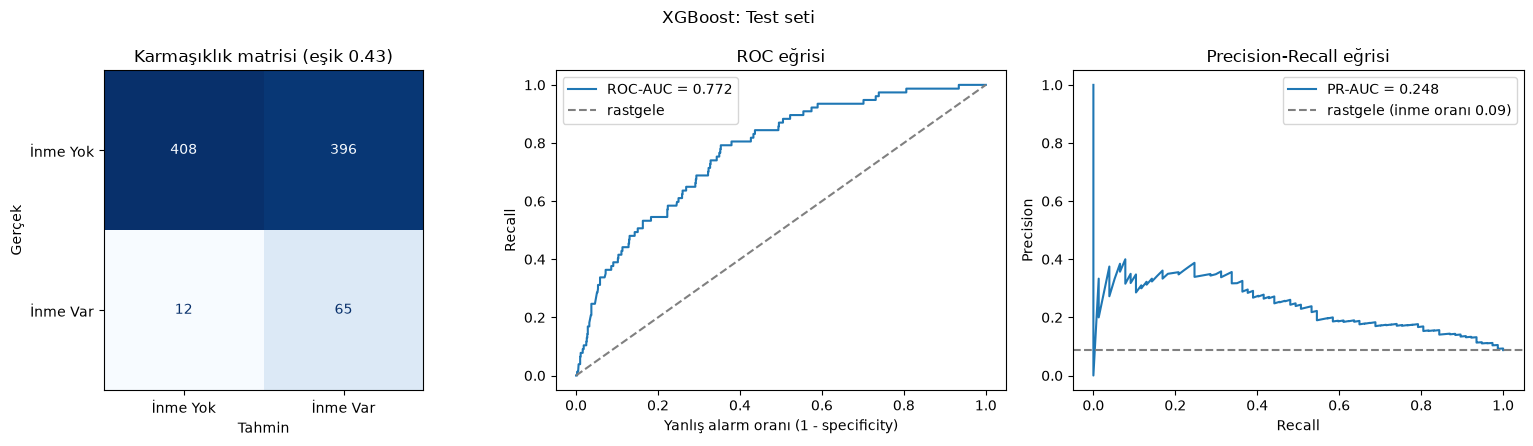

Model kaydedildi: models/xgb.joblib


In [13]:
best.fit(X_train, y_train)
test_result = test_evaluate(best, X_test, y_test, threshold=threshold,
                            model_name=MODEL_NAME, cv_result=cv_result)

joblib.dump(best, MODEL_DIR / f"{MODEL_CODE}.joblib")
print(f"Model kaydedildi: models/{MODEL_CODE}.joblib")

## 10. XAI: modelin açıklanması

XGBoost ağaç tabanlı bir model olduğu için ortak `explain()` fonksiyonu **TreeExplainer** kullanır: ağaçların iç yapısını doğrudan okuyarak SHAP değerlerini **kesin** ve hızlı hesaplar, tüm test seti kullanılır. XAI fonksiyonuna aramanın kendisi değil, `search.best_estimator_` (`best`) verilir.

**Not:** Boosting modellerinde SHAP değerleri **log-odds** ölçeğindedir (olasılık değil). Modeller arasında karşılaştırma yaparken ham değerler yerine `compare_importance()` fonksiyonunun verdiği yüzdeler kullanılmalıdır.

**Grafik okuma:** Bar grafiğinde çubuk uzunluğu önemi gösterir. Özet grafiğinde kırmızı = özelliğin değeri yüksek, mavi = düşük; nokta sağdaysa inme riskini artırıyor. LIME'da yeşil çubuklar "inme var" kararını destekleyen koşullardır.

===== XGBoost: XAI Analizi =====


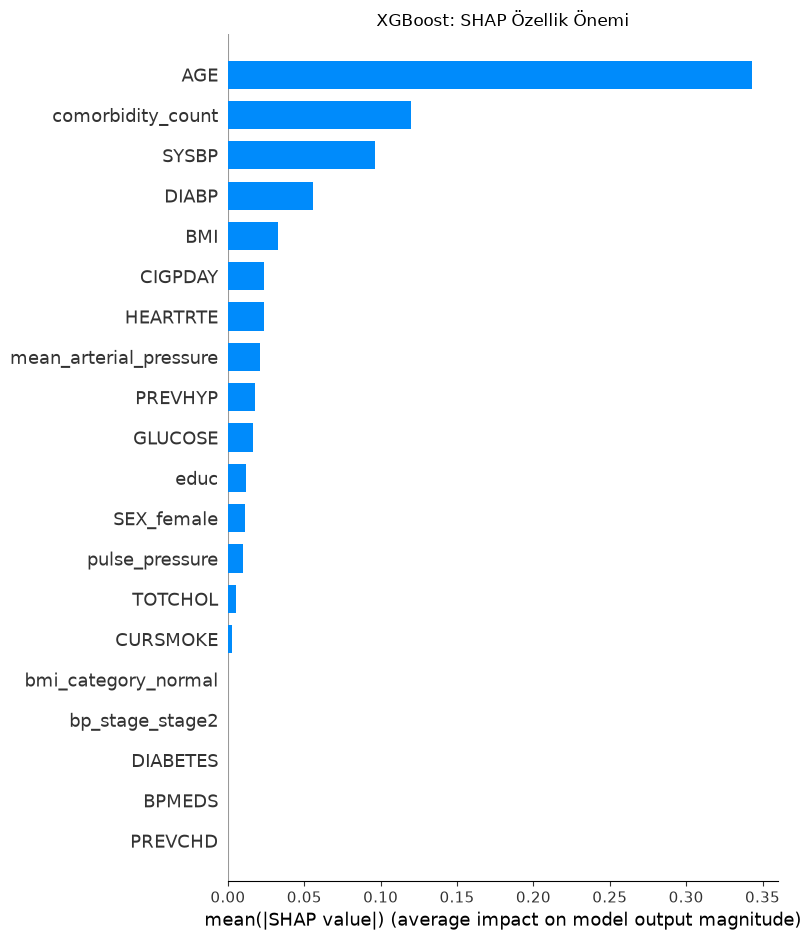

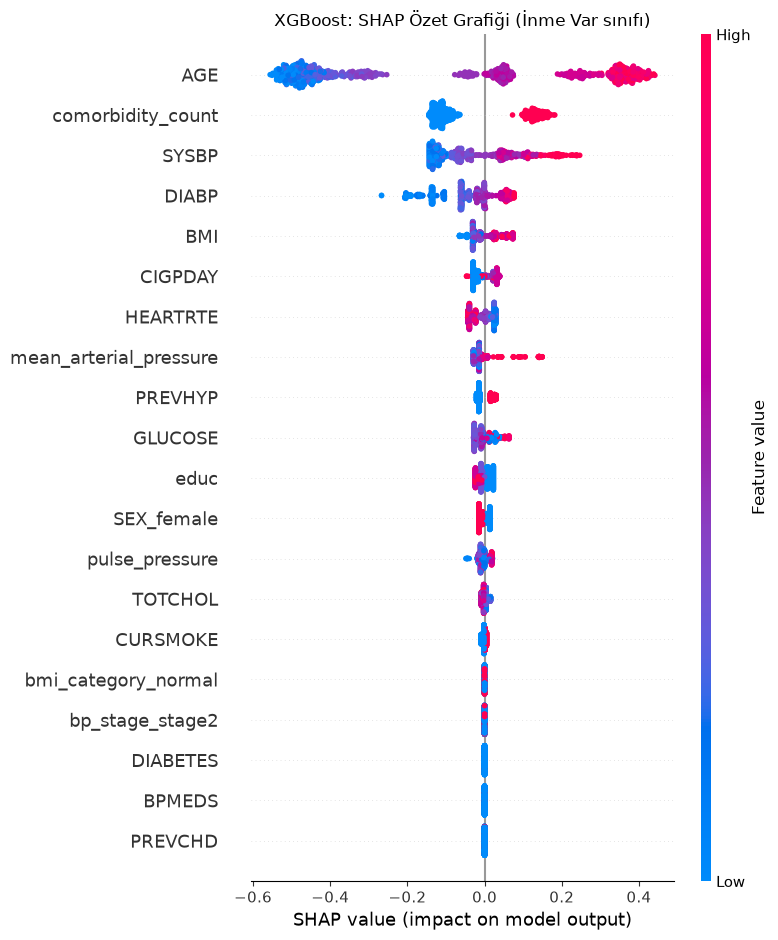


En önemli 5 özellik (SHAP):
          feature  mean_abs_shap
              AGE       0.342869
comorbidity_count       0.119566
            SYSBP       0.096510
            DIABP       0.055670
              BMI       0.032898

[XGBoost] Test hastası #559: İnme olasılığı = 73.30%


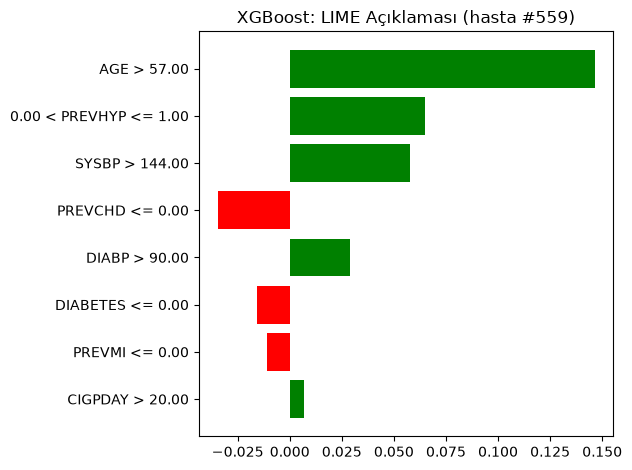


XAI süresi: 1 sn
Grafikler kaydedildi: ['xgb_lime.png', 'xgb_max_depth_overfitting.png', 'xgb_shap_bar.png', 'xgb_shap_summary.png']


In [14]:
# explain() grafikleri sırayla gösterir: SHAP bar, SHAP özet, LIME.
# Her grafik gösterilirken figures/ klasörüne de kaydedilir.
_names = iter([f"{MODEL_CODE}_shap_bar.png", f"{MODEL_CODE}_shap_summary.png", f"{MODEL_CODE}_lime.png"])
_show = plt.show
def _save_and_show(*args, **kwargs):
    name = next(_names, None)
    if name:
        plt.gcf().savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_and_show
try:
    start = time.time()
    xai = explain(best, X_train, X_test, model_name=MODEL_NAME)
    print(f"\nXAI süresi: {time.time() - start:.0f} sn")
finally:
    plt.show = _show
print("Grafikler kaydedildi:", [p.name for p in sorted(FIG_DIR.glob(f"{MODEL_CODE}_*.png"))])

In [15]:
xai["shap_importance"].head(10)

,feature,mean_abs_shap
0,AGE,0.342869
1,comorbidity_count,0.119566
2,SYSBP,0.096510
3,DIABP,0.055670
4,BMI,0.032898
5,CIGPDAY,0.023490
6,HEARTRTE,0.023352
7,mean_arterial_pressure,0.021270
8,PREVHYP,0.017537
9,GLUCOSE,0.016192
